<a href="https://colab.research.google.com/github/rahulkate173/Deep-Learning-Quest-/blob/main/Multihead_Latent_Attention_(Deepseek).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## Multihead Latent Attention {MLA}
## new proposed architecture for kv cache they able to compress it to 57X times the original attention in kv cache
## the proposed architecture use lower rank compression where the (X) is first compressed into lower latent space and then decompress back to key , value and this may introduce some memory bandwidth in
## computation of tensor but with efficient linear operation they make the attention better

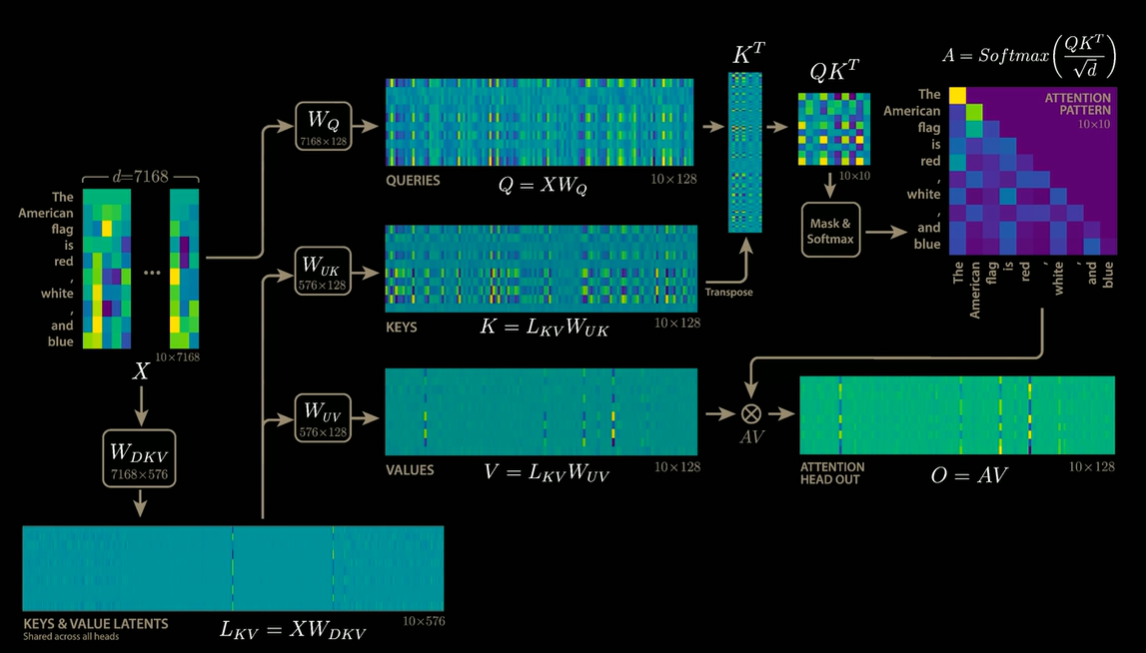

In [ ]:
## below reduce memeory bandwith by linear equation

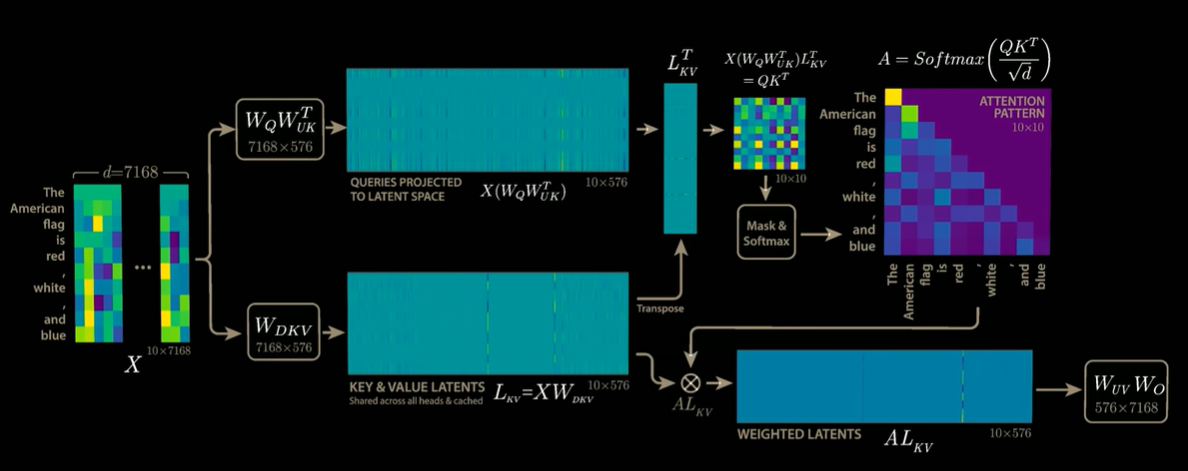

In [4]:
## let's implement
import torch
import torch.nn as nn
import numpy as np
from torch.nn import functional as F

In [35]:
## non optimize code
class MultiheadLatentAttention(nn.Module):
  def __init__(self,d_model=7168,kv_dim=576,num_heads=128):
    super().__init__()
    self.d_model = d_model
    # self.q_latent_dim = q_latent_dim
    self.kv_dim = kv_dim
    self.num_heads = num_heads

    self.w_dkv = nn.Linear(self.d_model,self.kv_dim)
    self.w_uk = nn.Linear(self.kv_dim,self.num_heads)
    self.w_uv = nn.Linear(self.kv_dim,self.num_heads)
    self.w_q = nn.Linear(self.d_model,self.num_heads)

  def forward(self,x):
    kv_latent = self.w_dkv(x)
    q = self.w_q(x)
    k = self.w_uk(kv_latent)
    v = self.w_uv(kv_latent)
    attention = F.softmax((q @ k.transpose(-1,-2))/torch.sqrt(torch.tensor(self.num_heads)))
    attention = attention @ v
    return attention

In [32]:
model =  MultiheadLatentAttention()
model

MultiheadLatentAttention(
  (w_dkv): Linear(in_features=7168, out_features=576, bias=True)
  (w_uk): Linear(in_features=576, out_features=128, bias=True)
  (w_uv): Linear(in_features=576, out_features=128, bias=True)
  (w_q): Linear(in_features=7168, out_features=128, bias=True)
)

In [33]:
x = torch.randn(10,7168)
x.shape

torch.Size([10, 7168])

In [34]:
model(x)

torch.Size([10, 128])
torch.Size([10, 128])


/tmp/ipykernel_721/1301735840.py:22: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  attention = F.softmax((q @ k.transpose(-1,-2))/torch.sqrt(torch.tensor(self.num_heads)))


tensor([[ 0.0450,  0.0193, -0.2563,  ..., -0.1068,  0.0048, -0.0134],
        [ 0.0547,  0.0152, -0.2071,  ..., -0.1328, -0.0348,  0.0245],
        [ 0.0786,  0.0008, -0.2134,  ..., -0.1070, -0.0167,  0.0114],
        ...,
        [ 0.0695,  0.0021, -0.2263,  ..., -0.1050, -0.0395, -0.0015],
        [ 0.0791, -0.0055, -0.2446,  ..., -0.1001,  0.0084, -0.0181],
        [ 0.0601,  0.0203, -0.2346,  ..., -0.1231,  0.0045,  0.0105]],
       grad_fn=<MmBackward0>)

In [38]:
## optimized mla
import torch
import torch.nn as nn
from torch.nn import functional as F

class MultiheadLatentAttentionOptimized(nn.Module):
    def __init__(self, d_model=7168, kv_dim=576, num_heads=128):
        super().__init__()
        self.d_model = d_model
        self.kv_dim = kv_dim
        self.num_heads = num_heads # Intermediate head dimension

        # Set bias=False so we can cleanly multiply the weight matrices together
        self.w_dkv = nn.Linear(self.d_model, self.kv_dim, bias=False)
        self.w_q = nn.Linear(self.d_model, self.num_heads, bias=False)
        self.w_uk = nn.Linear(self.kv_dim, self.num_heads, bias=False)

        self.w_uv = nn.Linear(self.kv_dim, self.num_heads, bias=False)
        self.w_o = nn.Linear(self.num_heads, self.d_model, bias=False) #

    def forward(self, x):
        kv_latents = self.w_dkv(x)
        absorbed_q_k_weight = self.w_q.weight.T @ self.w_uk.weight
        q_proj = x @ absorbed_q_k_weight
        scores = (q_proj @ kv_latents.transpose(-1, -2)) / torch.sqrt(torch.tensor(self.num_heads, dtype=torch.float32))
        A = F.softmax(scores, dim=-1)
        weighted_latents = A @ kv_latents
        absorbed_v_o_weight = self.w_uv.weight.T @ self.w_o.weight.T
        output = weighted_latents @ absorbed_v_o_weight

        return output


In [39]:
model_opt = MultiheadLatentAttentionOptimized()
x = torch.randn(10, 7168) # [seq_len, d_model]
out = model_opt(x)
print("Output shape:", out.shape) # Should be [10, 7168]

Output shape: torch.Size([10, 7168])
